Import thư viện

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

Set seed và generate data

y=3x+2+ϵ

In [2]:
torch.manual_seed(42)
x = torch.linspace(-5,5,200).unsqueeze(1)
noise = 0.5 * torch.randn_like(x)
y = 3.0 * x + 2.0 + noise

In [3]:
print("x shape: ", x.shape)
print("y shape: ", y.shape)
print("First 5 x: ")
print(x[:5])
print("First 5 y:")
print(y[:5])

x shape:  torch.Size([200, 1])
y shape:  torch.Size([200, 1])
First 5 x: 
tensor([[-5.0000],
        [-4.9497],
        [-4.8995],
        [-4.8492],
        [-4.7990]])
First 5 y:
tensor([[-12.0365],
        [-12.1056],
        [-12.2481],
        [-13.6005],
        [-12.0578]])


Train / Validation split

In [5]:
train_size = 160
x_train = x[:train_size]
y_train = y[:train_size]

x_val = x[train_size:]
y_val = y[train_size:]

print("Train: ")
print("x_train: ", x_train.shape)
print("y_train: ", y_train.shape)

print("\nValidation: ")
print("x_val: ", x_val.shape)
print("y_val: ", y_val.shape)

Train: 
x_train:  torch.Size([160, 1])
y_train:  torch.Size([160, 1])

Validation: 
x_val:  torch.Size([40, 1])
y_val:  torch.Size([40, 1])


Visualize dataset

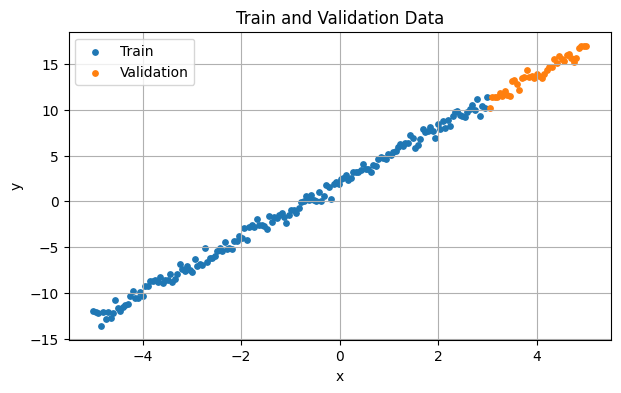

In [6]:
plt.figure(figsize=(7,4))
plt.scatter(
    x_train.numpy(),
    y_train.numpy(),
    s=15,
    label="Train"
)

plt.scatter(
    x_val.numpy(),
    y_val.numpy(),
    s=15,
    label="Validation"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Train and Validation Data")

plt.legend()
plt.grid(True)
plt.show()

Tạo model

In [8]:
model = nn.Linear(1,1)
criterion = nn.MSELoss()
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.05
)
print(model)
print("\nInitial weight:", model.weight.item())
print("Initial bias:", model.bias.item())

Linear(in_features=1, out_features=1, bias=True)

Initial weight: 0.4137152433395386
Initial bias: -0.38088154792785645


Nơi lưu loss

In [9]:
epochs = 500
train_losses = []
val_losses = []

Training loop

In [10]:
for epoch in range(epochs):
  # Training
  model.train()
  train_pred = model(x_train)
  train_loss = criterion(
      train_pred,
      y_train
  )
  optimizer.zero_grad()
  train_loss.backward()
  optimizer.step()

  # Validation
  model.eval()
  with torch.no_grad():
    val_pred = model(x_val)
    val_loss = criterion(
        val_pred,
        y_val
    )

  # Save loss
  train_losses.append(
      train_loss.item()
  )
  val_losses.append(
      val_loss.item()
  )

  # Print progress
  if epoch % 100 == 0:
    print(
        f"Epoch {epoch:03d} | "
        f"Train Loss: {train_loss.item():.4f} | "
        f"Val Loss: {val_loss.item():.4f}"
    )

Epoch 000 | Train Loss: 36.5415 | Val Loss: 49.9927
Epoch 100 | Train Loss: 0.2422 | Val Loss: 0.2469
Epoch 200 | Train Loss: 0.2422 | Val Loss: 0.2472
Epoch 300 | Train Loss: 0.2422 | Val Loss: 0.2472
Epoch 400 | Train Loss: 0.2422 | Val Loss: 0.2472


Final Evaluation

In [11]:
model.eval()

with torch.no_grad():

    train_pred = model(x_train)
    val_pred = model(x_val)

    final_train_loss = criterion(
        train_pred,
        y_train
    ).item()

    final_val_loss = criterion(
        val_pred,
        y_val
    ).item()

print("Final Train Loss:", final_train_loss)
print("Final Validation Loss:", final_val_loss)

Final Train Loss: 0.24222521483898163
Final Validation Loss: 0.24716277420520782


Lấy weight và bias

In [12]:
weight = model.weight.item()
bias = model.bias.item()

print("\nLearned parameters:")
print("weight =", weight)
print("bias   =", bias)


Learned parameters:
weight = 3.0085630416870117
bias   = 2.058758497238159


Vẽ train/validation loss

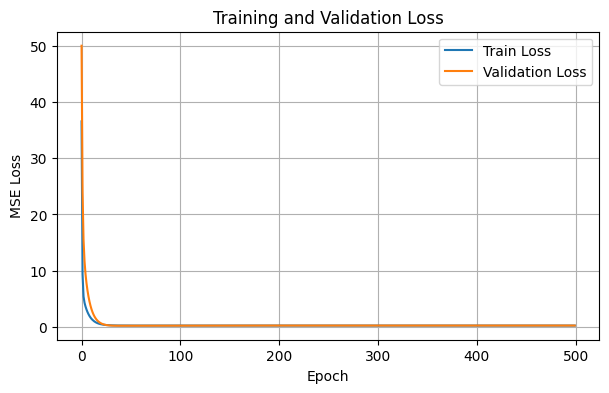

In [13]:
plt.figure(figsize=(7, 4))

plt.plot(
    train_losses,
    label="Train Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.grid(True)

plt.savefig(
    "loss_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Vẽ prediction

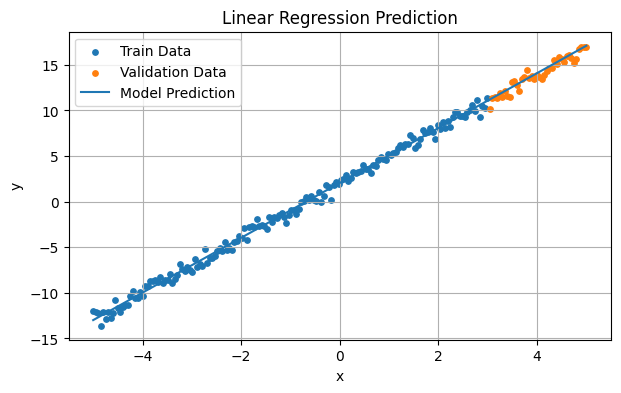

In [14]:
model.eval()

with torch.no_grad():
    all_pred = model(x)

plt.figure(figsize=(7, 4))

plt.scatter(
    x_train.numpy(),
    y_train.numpy(),
    s=15,
    label="Train Data"
)

plt.scatter(
    x_val.numpy(),
    y_val.numpy(),
    s=15,
    label="Validation Data"
)

plt.plot(
    x.numpy(),
    all_pred.numpy(),
    label="Model Prediction"
)

plt.xlabel("x")
plt.ylabel("y")
plt.title("Linear Regression Prediction")

plt.legend()
plt.grid(True)

plt.savefig(
    "prediction.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

Summary

In [15]:
print("\n" + "=" * 50)
print("PROJECT SUMMARY")
print("=" * 50)

print("True function: y = 3x + 2 + noise")

print(f"Learned weight:        {weight:.4f}")
print(f"Learned bias:          {bias:.4f}")

print(f"Final train loss:      {final_train_loss:.4f}")
print(f"Final validation loss: {final_val_loss:.4f}")

print("\nSaved figures:")
print("- loss_curve.png")
print("- prediction.png")


PROJECT SUMMARY
True function: y = 3x + 2 + noise
Learned weight:        3.0086
Learned bias:          2.0588
Final train loss:      0.2422
Final validation loss: 0.2472

Saved figures:
- loss_curve.png
- prediction.png
